In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tigramite
from tigramite import data_processing as pp
from tigramite.pcmci import PCMCI
from tigramite.independence_tests.parcorr import ParCorr    
import tigramite.plotting as tp

df = pd.read_excel("test.xlsx")

df["T"] = pd.to_datetime(df["T"])
df = df.sort_values("T")

var_names = [
    "X1",
    "X2",
    "X3",
    "X4"
]

data = df[var_names].to_numpy(dtype=float)

Integrează datele

In [38]:

if not np.isfinite(data).all():
    raise ValueError(
        "Data contains missing or infinite values. "
        "Handle these before running PCMCI+."
    )

print("Data dimensions:", data.shape)

Data dimensions: (260, 4)


Verfica datele

In [39]:
dataframe = pp.DataFrame(
    data,
    var_names=var_names
)



crează dataframe pentru tigramite

In [40]:
parcorr = ParCorr()

pcmci = PCMCI(
    dataframe=dataframe,
    cond_ind_test=parcorr,
    verbosity=1
)

Initializează PCMCI cu parcorr

In [41]:
results = pcmci.run_pcmciplus(
    tau_min=0,
    tau_max=6,
    pc_alpha=0.01,
    fdr_method="fdr_bh"
)


##
## Step 1: PC1 algorithm for selecting lagged conditions
##

Parameters:
independence test = par_corr
tau_min = 1
tau_max = 6
pc_alpha = [0.01]
max_conds_dim = None
max_combinations = 1



## Resulting lagged parent (super)sets:

    Variable X1 has 2 link(s):
        (X1 -1): max_pval = 0.00000, |min_val| =  0.685
        (X1 -4): max_pval = 0.00532, |min_val| =  0.177

    Variable X2 has 2 link(s):
        (X2 -1): max_pval = 0.00000, |min_val| =  0.689
        (X2 -4): max_pval = 0.00487, |min_val| =  0.179

    Variable X3 has 1 link(s):
        (X3 -1): max_pval = 0.00000, |min_val| =  0.646

    Variable X4 has 2 link(s):
        (X4 -1): max_pval = 0.00000, |min_val| =  0.488
        (X4 -2): max_pval = 0.00196, |min_val| =  0.197

##
## Step 2: PC algorithm with contemp. conditions and MCI tests
##

Parameters:

independence test = par_corr
tau_min = 0
tau_max = 6
pc_alpha = 0.01
contemp_collider_rule = majority
conflict_resolution = True
reset_lagged_links = False
max_con

Run PCMCI+

In [42]:

pcmci.print_significant_links(
    p_matrix=results["p_matrix"],
    val_matrix=results["val_matrix"],
    graph=results["graph"],
    ambiguous_triples=results["ambiguous_triples"],
    alpha_level=0.01
)


## Significant links at alpha = 0.01:

    Variable X1 has 2 link(s):
        (X1 -1): pval = 0.00000 | val =  0.631
        (X2  0): pval = 0.00324 | val =  0.189

    Variable X2 has 3 link(s):
        (X2 -1): pval = 0.00000 | val =  0.656
        (X2 -4): pval = 0.07657 | val =  0.180
        (X3  0): pval = 0.00654 | val =  0.173 | unoriented link

    Variable X3 has 2 link(s):
        (X3 -1): pval = 0.00000 | val =  0.613
        (X2  0): pval = 0.00654 | val =  0.173 | unoriented link

    Variable X4 has 4 link(s):
        (X4 -1): pval = 0.00000 | val =  0.477
        (X1  0): pval = 0.00000 | val =  0.326
        (X4 -2): pval = 0.07657 | val =  0.183
        (X2  0): pval = 0.00634 | val =  0.175

## Ambiguous triples (not used for orientation):

    [(X2 -1), X2, X1]
    [(X2 -4), X2, X1]
    [(X4 -1), X4, X1]
    [(X4 -2), X4, X1]
    [(X3 -1), X3, X2]
    [(X4 -2), X4, X2]
    [(X2 -1), X2, X3]
    [(X2 -4), X2, X3]
    [(X4  0), X2, X3]
    [(X2 -4), X2, X4]
    [(X3 

Arata rezultatele

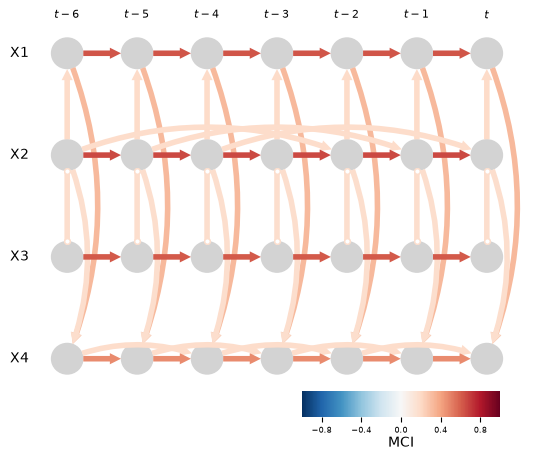

In [ ]:
tp.plot_time_series_graph(
    graph=results["graph"],
    val_matrix=results["val_matrix"],
    var_names=var_names
)

plt.show()
#arata

Graficul cauzal
